# Customer segmentation and 90-day customer value: Online Retail II

**Business question:** A UK online shop sells gift items, and many of its customers are wholesalers. Who are its best customers, who is slipping away, and which customers will bring the most money in the next 90 days?

**The data:** every invoice line of the shop from December 2009 to December 2011 (1,067,371 lines before cleaning). Each line has the invoice number, product code, quantity, date, unit price (in pounds), customer ID and country.

**Plan:**
1. Clean the data and write down every rule I use
2. **Segment** customers with RFM (Recency, Frequency, Monetary value) and compare the segments
3. Check the segments with a second method (k-means clustering)
4. **Predict** each customer's spend in the next 90 days, and test the model on a period it has never seen
5. Export tables for a dashboard

## 1. Set-up and data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, roc_auc_score, silhouette_score
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

csv_path, xlsx_path = DATA_DIR / "online_retail_II.csv", DATA_DIR / "online_retail_II.xlsx"
if csv_path.exists():
    raw = pd.read_csv(csv_path, parse_dates=["InvoiceDate"], dtype={"Invoice": str, "StockCode": str})
elif xlsx_path.exists():
    raw = pd.concat(pd.read_excel(xlsx_path, sheet_name=None, dtype={"Invoice": str, "StockCode": str}).values(),
                    ignore_index=True)
else:
    raise FileNotFoundError("Put online_retail_II.csv (or .xlsx) in the data/ folder. The README has the source.")

raw = raw.rename(columns={"Customer ID": "CustomerID"})
raw["Invoice"] = raw["Invoice"].astype(str)
raw.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [2]:
# Chart style: one colour per idea, the same in every chart.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_SOFT, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3de"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False,
})

### Cleaning rules
Each rule removes rows that would give wrong customer numbers. I log how many rows each rule removes.

1. **Exact duplicate lines** are removed.
2. **Lines without a customer ID** are removed. I cannot build customer-level numbers without an ID.
3. **Cancellations** (invoice number starts with `C`) are not counted as purchases or as visits. Their value is **subtracted from the customer's total spend** (net spend), so a cancelled order does not make a customer look better than they are. I show an example below.
4. **Lines with quantity or price of zero or less** are removed (these are adjustments, not sales).
5. **Non-product lines** are removed. Real products have a stock code that starts with 5 digits. Codes like `POST` (postage), `M` (manual entry), `BANK CHARGES` and `ADJUST` are fees and adjustments, not products.

In [3]:
log = [("Start", len(raw))]

tx = raw.drop_duplicates()
log.append(("1. Remove exact duplicate lines", len(tx)))

tx = tx[tx["CustomerID"].notna()]
log.append(("2. Remove lines without a customer ID", len(tx)))

cancelled = tx[tx["Invoice"].str.startswith("C")]          # keep for the size check below
tx = tx[~tx["Invoice"].str.startswith("C")]
log.append(("3. Remove cancellations", len(tx)))

tx = tx[(tx["Quantity"] > 0) & (tx["Price"] > 0)]
log.append(("4. Remove quantity or price <= 0", len(tx)))

tx = tx[tx["StockCode"].str.match(r"^\d{5}")]
log.append(("5. Keep product codes only", len(tx)))

tx = tx.assign(CustomerID=tx["CustomerID"].astype(int), Revenue=tx["Quantity"] * tx["Price"]).reset_index(drop=True)

# Cancelled lines get the same product and price rules. Their revenue is negative (the quantity is negative).
returns = cancelled[(cancelled["Price"] > 0) & cancelled["StockCode"].str.match(r"^\d{5}")]
returns = returns.assign(CustomerID=returns["CustomerID"].astype(int), Revenue=returns["Quantity"] * returns["Price"])

# One table with purchases and cancellations. It is used for net spend.
ledger = pd.concat([tx[["CustomerID", "InvoiceDate", "Revenue"]], returns[["CustomerID", "InvoiceDate", "Revenue"]]],
                   ignore_index=True)

clean_log = pd.DataFrame(log, columns=["step", "rows left"])
clean_log["rows removed"] = (-clean_log["rows left"].diff()).fillna(0).astype(int)
clean_log

,step,rows left,rows removed
0,Start,1067371,0
1,1. Remove exact duplicate lines,1033036,34335
2,2. Remove lines without a customer ID,797885,235151
3,3. Remove cancellations,779495,18390
4,4. Remove quantity or price <= 0,779425,70
5,5. Keep product codes only,776577,2848


In [4]:
print(f"Clean data: {len(tx):,} lines, {tx['CustomerID'].nunique():,} customers, {tx['Invoice'].nunique():,} invoices")
print(f"Period: {tx['InvoiceDate'].min():%d %b %Y} to {tx['InvoiceDate'].max():%d %b %Y}")
print(f"Purchases (before cancellations): £{tx['Revenue'].sum():,.0f}")
print(f"Cancelled value: £{-returns['Revenue'].sum():,.0f} = {-returns['Revenue'].sum() / tx['Revenue'].sum():.1%} of purchases")
print(f"Net revenue (purchases minus cancellations): £{ledger['Revenue'].sum():,.0f}")

Clean data: 776,577 lines, 5,852 customers, 36,594 invoices
Period: 01 Dec 2009 to 09 Dec 2011
Purchases (before cancellations): £17,068,568
Cancelled value: £709,953 = 4.2% of purchases
Net revenue (purchases minus cancellations): £16,358,615


In [5]:
# Why net spend matters: the customer with the biggest single order
by_customer = pd.DataFrame({
    "purchases (£)": tx.groupby("CustomerID")["Revenue"].sum(),
    "cancelled (£)": -returns.groupby("CustomerID")["Revenue"].sum(),
}).fillna(0)
by_customer["net spend (£)"] = by_customer["purchases (£)"] - by_customer["cancelled (£)"]
biggest_order_customer = tx.loc[tx["Revenue"].idxmax(), "CustomerID"]
by_customer.loc[[biggest_order_customer]].round(2)

,purchases (£),cancelled (£),net spend (£)
CustomerID,,,
16446,168472.5,168469.6,2.9


About 4% of purchase value was cancelled. The customer with the biggest single order shows why this matters: that customer bought about £168,000 and cancelled almost all of it, so the net spend is only £2.90. Without the subtraction, this customer would look like the biggest spender in the data.

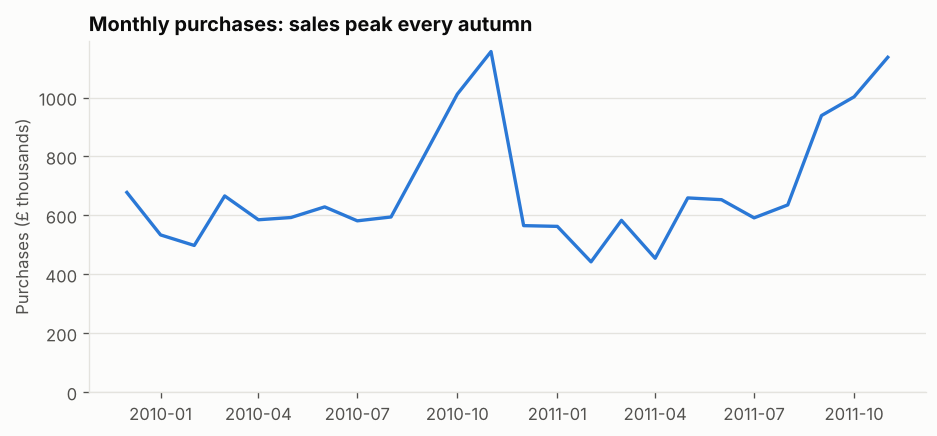

In [6]:
# Chart 1: purchases by month (before cancellations). This shows the strong season in autumn.
monthly = tx.set_index("InvoiceDate")["Revenue"].resample("MS").sum()
monthly = monthly[monthly.index < monthly.index.max()]    # the last month is cut short in the data, so I drop it

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(monthly.index, monthly.values / 1000, color=BLUE, linewidth=2)
ax.set_ylabel("Purchases (£ thousands)")
ax.set_title("Monthly purchases: sales peak every autumn")
ax.set_ylim(0, None)
ax.grid(axis="x", visible=False)
plt.show()

Sales peak every autumn (gift season). This matters later: a model trained on summer data will see a very different picture in autumn.

## 2. RFM segmentation
RFM describes every customer with three numbers, measured at a snapshot date (the day after the last invoice in the data):
- **Recency:** days since the last purchase (lower is better)
- **Frequency:** number of invoices
- **Monetary value:** total net spend in pounds (purchases minus cancellations)

Each number is turned into a score from 1 to 5, using five equal-size groups (quintiles). Then I give each customer a segment name from simple rules on the R and F scores. I use R and F only, because spend (M) follows frequency closely.

In [7]:
SNAPSHOT = tx["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)


def rfm_table(data, money, snapshot):
    """data = purchases, money = purchases and cancellations (for net spend)."""
    g = data.groupby("CustomerID")
    out = pd.DataFrame({
        "recency_days": (snapshot - g["InvoiceDate"].max()).dt.days,
        "frequency": g["Invoice"].nunique(),
        "monetary": money.groupby("CustomerID")["Revenue"].sum().reindex(g.size().index).fillna(0),
    })
    # rank(method="first") breaks ties, so the five groups have (almost) equal size
    out["R"] = pd.qcut(out["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
    out["F"] = pd.qcut(out["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    out["M"] = pd.qcut(out["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    return out


def name_segment(r, f):
    return np.select(
        [(r >= 4) & (f >= 4), (r >= 3) & (f >= 3), (r >= 4) & (f <= 2), (r == 3) & (f <= 2), (r <= 2) & (f >= 3)],
        ["Champions", "Loyal", "Recent", "Needs attention", "At risk"],
        default="Lost",
    )


rfm = rfm_table(tx, ledger, SNAPSHOT)
rfm["segment"] = name_segment(rfm["R"].to_numpy(), rfm["F"].to_numpy())
print("Snapshot date:", SNAPSHOT.date())
rfm.head()

Snapshot date: 2011-12-10


,recency_days,frequency,monetary,R,F,M,segment
CustomerID,,,,,,,
12346,325,3,169.36,2,3,1,At risk
12347,2,8,4921.53,5,4,5,Champions
12348,75,5,1658.40,3,4,4,Loyal
12349,18,3,3654.54,5,3,5,Loyal
12350,310,1,294.40,2,1,2,Lost


In [8]:
summary = rfm.groupby("segment").agg(
    customers=("monetary", "size"),
    net_spend=("monetary", "sum"),
    avg_recency_days=("recency_days", "mean"),
    avg_orders=("frequency", "mean"),
    avg_spend=("monetary", "mean"),
)
summary["% of customers"] = summary["customers"] / summary["customers"].sum() * 100
summary["% of revenue"] = summary["net_spend"] / summary["net_spend"].sum() * 100
summary = summary.sort_values("% of revenue", ascending=False)
summary.round({"net_spend": 0, "avg_recency_days": 0, "avg_orders": 1, "avg_spend": 0, "% of customers": 1, "% of revenue": 1})

,customers,net_spend,avg_recency_days,avg_orders,avg_spend,% of customers,% of revenue
segment,,,,,,,
Champions,1463,11467599.0,20.0,15.6,7838.0,25.0,70.1
Loyal,1218,2411589.0,77.0,5.4,1980.0,20.8,14.7
At risk,830,1436919.0,367.0,5.0,1731.0,14.2,8.8
Lost,1511,605389.0,456.0,1.2,401.0,25.8,3.7
Recent,447,238157.0,27.0,1.5,533.0,7.6,1.5
Needs attention,383,200367.0,105.0,1.4,523.0,6.5,1.2


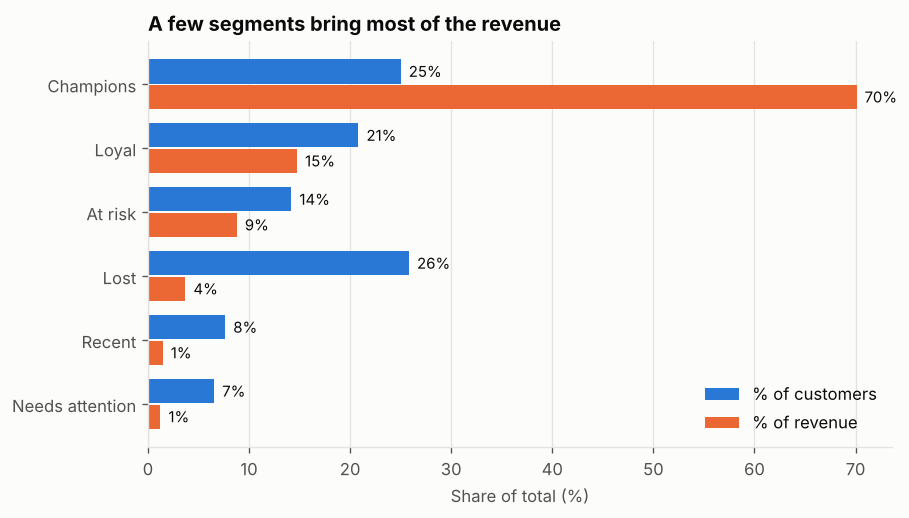

In [9]:
# Chart 2: share of customers against share of revenue, by segment.
order = summary.index[::-1]                     # largest revenue share at the top
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(y + 0.2, summary.loc[order, "% of customers"], height=0.38, color=BLUE, label="% of customers")
ax.barh(y - 0.2, summary.loc[order, "% of revenue"], height=0.38, color=ORANGE, label="% of revenue")
for yi, seg in zip(y, order):
    ax.text(summary.loc[seg, "% of customers"] + 0.8, yi + 0.2, f"{summary.loc[seg, '% of customers']:.0f}%", va="center", fontsize=9)
    ax.text(summary.loc[seg, "% of revenue"] + 0.8, yi - 0.2, f"{summary.loc[seg, '% of revenue']:.0f}%", va="center", fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.set_xlabel("Share of total (%)")
ax.set_title("A few segments bring most of the revenue")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()

### A second method: k-means clustering
RFM rules are easy to explain, but the cut-offs are my choice. As a check, I let k-means find groups from the data itself. Recency, frequency and spend are very skewed, so I take the logarithm and scale each to the same range first. I pick the number of clusters (k) with the **silhouette score** (higher means better-separated clusters).

In [10]:
# Net spend can be zero or below for a few customers (cancellations bigger than purchases), so I set it to 0 before the log.
features = StandardScaler().fit_transform(np.log1p(rfm[["recency_days", "frequency", "monetary"]].clip(lower=0)))

sil = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(features)
    sil[k] = silhouette_score(features, labels)
pd.Series(sil, name="silhouette score").rename_axis("k").round(3).to_frame().T

k,2,3,4,5,6,7,8
silhouette score,0.436,0.344,0.36,0.337,0.329,0.295,0.296


In [11]:
best_k = max(sil, key=sil.get)
print(f"Best k by silhouette score: {best_k}")
# The best k is often 2, which is too coarse to be useful for marketing. I use 4 and report both scores.
K_USED = 4
rfm["cluster"] = KMeans(n_clusters=K_USED, n_init=10, random_state=0).fit_predict(features)
cluster_profile = rfm.groupby("cluster").agg(
    customers=("monetary", "size"),
    median_recency_days=("recency_days", "median"),
    median_orders=("frequency", "median"),
    median_spend=("monetary", "median"),
)
print(f"k = {K_USED}: silhouette score = {sil[K_USED]:.3f}")
cluster_profile

Best k by silhouette score: 2
k = 4: silhouette score = 0.360


,customers,median_recency_days,median_orders,median_spend
cluster,,,,
0,1980,400.0,1.0,263.495
1,1234,23.0,3.0,711.565
2,1483,176.0,5.0,1444.580
3,1155,16.0,13.0,4921.530


In [12]:
pd.crosstab(rfm["segment"], rfm["cluster"], normalize="index").mul(100).round(0).astype(int)

cluster,0,1,2,3
segment,,,,
At risk,23,0,75,2
Champions,0,21,9,71
Lost,95,0,5,0
Loyal,4,38,50,9
Needs attention,71,19,11,0
Recent,9,91,0,0


**Reading:** the best silhouette score is for k = 2 (0.436). That split is only "active" against "inactive" customers, which is too coarse to act on, so I use k = 4 (silhouette score 0.360). A score of 0.36 means the clusters overlap: customers form a continuum more than clear groups.
Still, the two methods **agree on the main groups**:
- 71% of Champions are in cluster 3 (median 13 orders, £4,922 spend, last bought 16 days ago)
- 95% of Lost customers are in cluster 0 (median 1 order, last bought 400 days ago)
- 91% of Recent customers are in cluster 1, and 75% of At risk customers are in cluster 2

The RFM names are easier to explain to a marketing team, so I use them in the exports.

## 3. Predicting spend in the next 90 days
**Goal:** rank customers by how much they will spend in the next 90 days, so the team knows where to put effort.

**Method:** I use the past to predict a later period, and I test on a period the model has never seen:
- For a *cutoff date*, I build features from all purchases **before** the cutoff, and the target is spend in the **90 days after** the cutoff.
- **Training:** cutoff 180 days before the end of the data (the target is the middle 90 days).
- **Test:** cutoff 90 days before the end of the data (the target is the last 90 days). The model never sees these outcomes in training, so this is an honest test.

The model has two parts: (1) the probability that the customer buys at all in the next 90 days, and (2) how much they spend if they do (modelled on the log scale, because spend is very skewed). Expected value = probability x expected spend.

**Target:** purchases in the 90 days after the cutoff (before cancellations).

**Features:** recency, frequency, net spend, average order value, days since first purchase, orders and spend in the last 90 days before the cutoff, and a UK flag.

In [13]:
HORIZON = pd.Timedelta(days=90)
FEATURES = ["recency_days", "frequency", "monetary", "avg_order_value", "tenure_days",
            "orders_last_90d", "spend_last_90d", "is_uk"]
uk_customers = set(raw.loc[raw["Country"] == "United Kingdom", "CustomerID"].dropna().astype(int))


def build_features(data, money, cutoff, with_target=True):
    """data = purchases, money = purchases and cancellations. Only information before the cutoff is used."""
    past = data[data["InvoiceDate"] < cutoff]
    g = past.groupby("CustomerID")
    past_money = money[money["InvoiceDate"] < cutoff].groupby("CustomerID")["Revenue"].sum()
    feat = pd.DataFrame({
        "recency_days": (cutoff - g["InvoiceDate"].max()).dt.days,
        "frequency": g["Invoice"].nunique(),
        "monetary": past_money.reindex(g.size().index).fillna(0),
        "tenure_days": (cutoff - g["InvoiceDate"].min()).dt.days,
    })
    feat["avg_order_value"] = feat["monetary"] / feat["frequency"]
    recent = past[past["InvoiceDate"] >= cutoff - HORIZON].groupby("CustomerID")
    feat["orders_last_90d"] = recent["Invoice"].nunique().reindex(feat.index).fillna(0)
    feat["spend_last_90d"] = recent["Revenue"].sum().reindex(feat.index).fillna(0)
    feat["is_uk"] = feat.index.isin(uk_customers).astype(int)
    if with_target:
        future = data[(data["InvoiceDate"] >= cutoff) & (data["InvoiceDate"] < cutoff + HORIZON)]
        feat["target"] = future.groupby("CustomerID")["Revenue"].sum().reindex(feat.index).fillna(0)
    return feat


TEST_CUTOFF = SNAPSHOT - HORIZON
TRAIN_CUTOFF = TEST_CUTOFF - HORIZON
train = build_features(tx, ledger, TRAIN_CUTOFF)
test = build_features(tx, ledger, TEST_CUTOFF)
print(f"Training: features before {TRAIN_CUTOFF.date()}, target = spend {TRAIN_CUTOFF.date()} to {(TRAIN_CUTOFF + HORIZON).date()}  ({len(train):,} customers)")
print(f"Test:     features before {TEST_CUTOFF.date()}, target = spend {TEST_CUTOFF.date()} to {(TEST_CUTOFF + HORIZON).date()}  ({len(test):,} customers)")
print(f"Customers who bought in the target period: training {(train['target'] > 0).mean():.1%}, test {(test['target'] > 0).mean():.1%}")
print(f"Average spend per customer in the target period: training £{train['target'].mean():,.0f}, test £{test['target'].mean():,.0f}")

Training: features before 2011-06-13, target = spend 2011-06-13 to 2011-09-11  (4,952 customers)
Test:     features before 2011-09-11, target = spend 2011-09-11 to 2011-12-10  (5,256 customers)
Customers who bought in the target period: training 32.1%, test 43.6%
Average spend per customer in the target period: training £336, test £569


In [14]:
class TwoPartModel:
    """Expected spend = P(buys) x expected spend if buys."""

    def __init__(self, seed=0):
        params = dict(max_depth=3, learning_rate=0.05, max_iter=200, random_state=seed)
        self.clf = HistGradientBoostingClassifier(**params)
        self.reg = HistGradientBoostingRegressor(**params)

    def fit(self, X, spend):
        buys = spend > 0
        self.clf.fit(X, buys)
        self.reg.fit(X[buys], np.log(spend[buys]))
        # Smearing factor: undo the bias of predicting on the log scale
        self.smear = float(np.mean(np.exp(np.log(spend[buys]) - self.reg.predict(X[buys]))))
        return self

    def predict_prob(self, X):
        return self.clf.predict_proba(X)[:, 1]

    def predict_spend_if_buys(self, X):
        return np.exp(self.reg.predict(X)) * self.smear

    def predict(self, X):
        return self.predict_prob(X) * self.predict_spend_if_buys(X)


model = TwoPartModel().fit(train[FEATURES], train["target"])
test["predicted"] = model.predict(test[FEATURES])

# Two simple baselines to beat
test["baseline_last_90d"] = test["spend_last_90d"]                                  # "same as the last 90 days"
test["baseline_daily_rate"] = test["monetary"].clip(lower=0) / (test["tenure_days"] + 1) * 90     # average daily spend x 90
print("Model built. Test customers scored:", len(test))

Model built. Test customers scored: 5256


### How good is the model on the unseen test period?
I compare it with the two simple baselines. I use three views:
- **MAE** (mean absolute error in pounds per customer): lower is better. Spend is skewed, so MAE is dominated by big customers.
- **Spearman correlation** between predicted and actual spend: does the model put customers in the right order?
- **Top-10% capture:** what share of the real spend came from the 10% of customers the model ranked highest?

In [15]:
def top_share(score, actual, share=0.10):
    n = max(1, int(len(score) * share))
    top = np.argsort(-np.asarray(score), kind="stable")[:n]
    return np.asarray(actual)[top].sum() / np.sum(actual)


rows = []
for name, col in [("Model", "predicted"), ("Baseline: same as last 90 days", "baseline_last_90d"),
                  ("Baseline: average daily spend x 90", "baseline_daily_rate")]:
    rows.append({
        "approach": name,
        "MAE (£ per customer)": mean_absolute_error(test["target"], test[col]),
        "Spearman correlation": stats.spearmanr(test[col], test["target"]).statistic,
        "top-10% capture": top_share(test[col], test["target"]),
        "total predicted (£)": test[col].sum(),
    })
rows.append({"approach": "Best possible ranking (knows the future)", "MAE (£ per customer)": np.nan,
             "Spearman correlation": 1.0, "top-10% capture": top_share(test["target"], test["target"]),
             "total predicted (£)": test["target"].sum()})
evaluation = pd.DataFrame(rows).set_index("approach")
evaluation.round({"MAE (£ per customer)": 0, "Spearman correlation": 3, "top-10% capture": 3, "total predicted (£)": 0})

,MAE (£ per customer),Spearman correlation,top-10% capture,total predicted (£)
approach,,,,
Model,423.0,0.565,0.560,1779928.0
Baseline: same as last 90 days,450.0,0.478,0.532,1817273.0
Baseline: average daily spend x 90,516.0,0.532,0.557,2858291.0
Best possible ranking (knows the future),NaN,1.000,0.733,2990827.0


In [16]:
auc = roc_auc_score(test["target"] > 0, model.predict_prob(test[FEATURES]))
print(f"Part 1 (will the customer buy at all?): AUC = {auc:.3f}   (0.5 = guessing, 1.0 = perfect)")
print(f"Actual total spend in the test period: £{test['target'].sum():,.0f}")
print(f"Predicted total spend in the test period: £{test['predicted'].sum():,.0f}  ({test['predicted'].sum() / test['target'].sum() - 1:+.1%} against actual)")

Part 1 (will the customer buy at all?): AUC = 0.795   (0.5 = guessing, 1.0 = perfect)
Actual total spend in the test period: £2,990,827
Predicted total spend in the test period: £1,779,928  (-40.5% against actual)


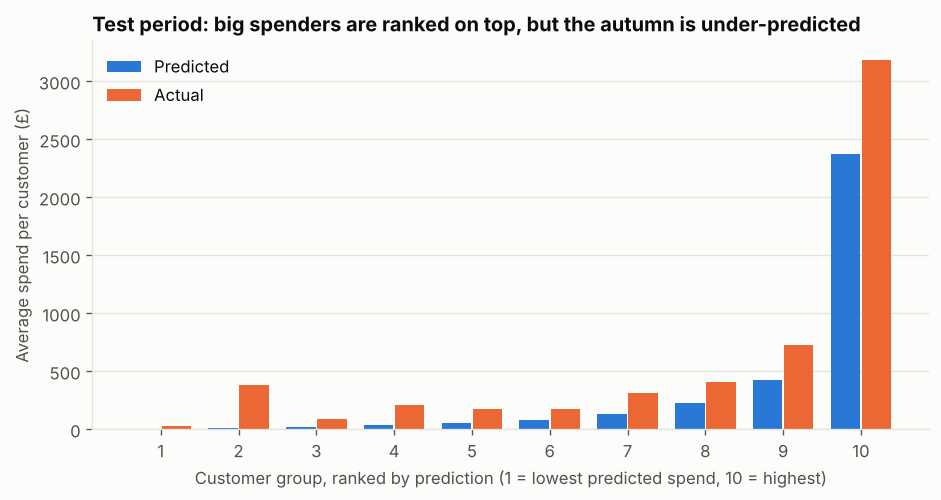

In [17]:
# Chart 3: predicted against actual spend, by group of customers ranked by prediction.
test["decile"] = pd.qcut(test["predicted"].rank(method="first"), 10, labels=range(1, 11)).astype(int)
calib = test.groupby("decile")[["predicted", "target"]].mean()

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(1, 11)
ax.bar(x - 0.2, calib["predicted"], width=0.38, color=BLUE, label="Predicted")
ax.bar(x + 0.2, calib["target"], width=0.38, color=ORANGE, label="Actual")
ax.set_xticks(x)
ax.set_xticklabels([f"{d}" for d in x])
ax.set_xlabel("Customer group, ranked by prediction (1 = lowest predicted spend, 10 = highest)")
ax.set_ylabel("Average spend per customer (£)")
ax.set_title("Test period: big spenders are ranked on top, but the autumn is under-predicted")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
plt.show()

In [18]:
# Which features matter for part 1? (permutation importance on the test set: how much does AUC drop if a feature is shuffled?)
imp = permutation_importance(model.clf, test[FEATURES], test["target"] > 0, scoring="roc_auc",
                             n_repeats=10, random_state=0)
pd.Series(imp.importances_mean, index=FEATURES, name="AUC drop when shuffled").sort_values(ascending=False).round(4).to_frame()

,AUC drop when shuffled
recency_days,0.0773
frequency,0.0227
monetary,0.0221
tenure_days,0.0041
spend_last_90d,0.0026
orders_last_90d,0.0023
avg_order_value,0.0014
is_uk,0.0001


**Reading:**
- **The model beats the baselines, but only by a little.** MAE is £423 per customer, against £450 for "same as the last 90 days" and £516 for "average daily spend x 90". Rank correlation is 0.565, against 0.478 and 0.532. The top 10% of customers ranked by the model produced 56.0% of the real spend, while the daily-rate baseline gets 55.7%. So for finding the top customers, a simple rule is almost as good as the model. A perfect ranking would capture 73.3%.
- **The model is decent at telling who will buy at all** (AUC 0.795). Recency is by far the most important feature: how long ago a customer last bought matters more than how much they spent.
- **The totals are about 40% too low** (£1.78 million predicted, £2.99 million actual). The test period is the autumn peak: 43.6% of customers bought in it (32.1% in the training period), and average spend was £569 per customer (£336 in training). A model trained on summer data cannot know that autumn will be busier. Ranking still works at the top (the group with the highest predictions has by far the highest actual spend; the low groups are noisy), but **the pound values should not be used as a forecast**.
- Possible fixes: add the month of the year as a feature, or train on several full years. This data has only two years, so the model sees only one autumn.

## 4. Score all customers and export tables for a dashboard
For the final scores I retrain the model on both windows (training and test), then score every customer **as of the snapshot date**. The result is a ranking tool: use it to order customers, not to promise exact money. The 90 days after the end of the data (mid December to early March) are a different season from the training windows, so the pound values are only a rough guide. I save three small tables. A dashboard tool such as Looker Studio can read them as CSV files.

In [19]:
final_train = pd.concat([train, test[train.columns]])
final_model = TwoPartModel().fit(final_train[FEATURES], final_train["target"])

now = build_features(tx, ledger, SNAPSHOT, with_target=False)
now["predicted_next_90d_spend"] = final_model.predict(now[FEATURES])
now["probability_buys_next_90d"] = final_model.predict_prob(now[FEATURES])

customers_out = (rfm[["recency_days", "frequency", "monetary", "R", "F", "M", "segment", "cluster"]]
                 .join(now[["probability_buys_next_90d", "predicted_next_90d_spend"]])
                 .assign(is_uk=lambda d: d.index.isin(uk_customers).astype(int))
                 .reset_index())
customers_out["monetary"] = customers_out["monetary"].round(2)
customers_out["predicted_next_90d_spend"] = customers_out["predicted_next_90d_spend"].round(2)
customers_out["probability_buys_next_90d"] = customers_out["probability_buys_next_90d"].round(4)

segment_out = summary.reset_index().round(2)
monthly_out = monthly.rename("revenue").round(2).reset_index().rename(columns={"InvoiceDate": "month"})

customers_out.to_csv(OUT_DIR / "customers_segments_and_value.csv", index=False)
segment_out.to_csv(OUT_DIR / "segment_summary.csv", index=False)
monthly_out.to_csv(OUT_DIR / "monthly_revenue.csv", index=False)
print("Saved to outputs/:", sorted(p.name for p in OUT_DIR.glob("*.csv")))
customers_out.sort_values("predicted_next_90d_spend", ascending=False).head(10)

Saved to outputs/: ['customers_segments_and_value.csv', 'monthly_revenue.csv', 'segment_summary.csv']


,CustomerID,recency_days,frequency,monetary,R,F,M,segment,cluster,probability_buys_next_90d,predicted_next_90d_spend,is_uk
2262,14646,1,145,523202.74,5,5,5,Champions,3,0.9852,60576.40,0
1778,14156,9,144,297775.01,5,5,5,Champions,3,0.9865,60299.31,0
5026,17450,8,51,233643.91,5,5,5,Champions,3,0.9646,59766.65,1
5085,17511,2,60,168504.44,5,5,5,Champions,3,0.9852,47876.03,1
4271,16684,4,55,141530.29,5,5,5,Champions,3,0.9865,46699.01,1
5514,17949,1,116,98469.06,5,5,5,Champions,3,0.9852,42926.51,1
5666,18102,0,145,578408.64,5,5,5,Champions,3,0.9852,42059.57,1
2520,14911,1,373,258522.43,5,5,5,Champions,3,0.9852,39122.03,0
3369,15769,7,46,84183.52,5,5,5,Champions,3,0.9865,38491.67,1
3625,16029,38,106,97066.71,4,5,5,Champions,3,0.9800,37885.54,1


## 5. Summary

**Segments**
- **Champions** are 25% of customers and bring **70% of net revenue**. They bought 20 days before the snapshot on average, with about 16 orders each.
- **Lost** customers are 26% of customers but only 4% of revenue. Most bought once.
- **At risk** customers (14% of customers, 9% of revenue) bought 5 orders on average, but not for about a year. They are the best group to try to win back, because they used to buy often.
- A second method (k-means) finds the same main groups.

**Prediction**
- Recency (days since the last purchase) is the strongest signal of who will buy again.
- The model ranks customers a bit better than simple rules, and is clearly better than guessing (AUC 0.795), but the gain over a simple rule is small.
- The predicted amounts are too low in the test period because of the autumn peak. Use the scores to rank customers, not as a money forecast.

**Limits**
- About 23% of invoice lines have no customer ID. They are not in this analysis.
- Cancellations are subtracted from net spend, but the model target counts purchases only.
- One shop, two years of data, many wholesale customers. Results may not hold for other businesses.
- I did not try to tune the model much. It is a clear and honest starting point, not a finished system.

**Next steps:** add seasonality to the model, add product-level features (what customers buy), and test the segments with a real campaign (for example a win-back offer for the At risk group against a control group).